# Mangrove Pulse: end-to-end evidence review

**Team:** Taimaa Ghazal, Team Leader & Concept Development Lead; Salim Ammar, Technical Lead & Team Presenter.

Historical Khor Kalba satellite evidence → reference uncertainty → observation requests → conditional platform choice.

This notebook reproduces the unchanged cached Sentinel-2/GMW baseline and audit, displays completed reference-sensitivity results, validates all 85 historical centres and exports empty observation records. It performs no new EO acquisition or threshold tuning and supplies no field measurements, ecological diagnosis or aircraft operation. The [original executed companion](../Mangrove_Pulse_End_to_End_Executed.ipynb) preserves the recorded run; this source copy has revised prose and unchanged code.

Reference agreement is not field accuracy. The hyper-drone concept has no implemented hyperspectral sensor or aircraft, and no planting or carbon benefit has been demonstrated. C001/C017 may require only imagery; contact sensing associated with C027 needs a separately justified current task and permission. Current observations cannot directly validate 2018 cover.

The portable executed version embeds its exact repository snapshot. This source version locates a checkout or accepts its repository ZIP. Run cells in order and save the notebook with its actual outputs. Failed runs export diagnostics; partial files are not successful results.


In [3]:
from google.colab import drive
drive.mount("/content/drive")
# Release verification wrapper: cached input only; no scientific code is changed.
import base64, hashlib, io, json, tempfile, zipfile
from pathlib import Path, PurePosixPath
_rv_snapshot = Path("/content/drive/MyDrive/Mangrove_Pulse_Release_cb4b400.zip").read_bytes()
_rv_snapshot_hash = "28aa20c925b8ddccf327f30e5e1408e716aa397960e7e7b7e1da7b2ddff6ccc6"
if hashlib.sha256(_rv_snapshot).hexdigest() != _rv_snapshot_hash: raise ValueError('Snapshot hash mismatch')
_rv_container = Path(tempfile.mkdtemp(prefix='mp_release_snapshot_'))
with zipfile.ZipFile(io.BytesIO(_rv_snapshot)) as _rv_zip:
    _rv_entries = _rv_zip.infolist()
    if len({_e.filename for _e in _rv_entries}) != len(_rv_entries): raise ValueError('Duplicate snapshot paths')
    if sum(_e.file_size for _e in _rv_entries) > 100_000_000: raise ValueError('Snapshot too large')
    for _e in _rv_entries:
        _p = PurePosixPath(_e.filename)
        if _p.is_absolute() or '..' in _p.parts or ':' in _e.filename or chr(92) in _e.filename: raise ValueError('Unsafe snapshot path')
        if (_e.external_attr >> 16) & 0o170000 == 0o120000: raise ValueError('Snapshot symlink refused')
    if _rv_zip.testzip() is not None: raise ValueError('Snapshot CRC failure')
    _rv_zip.extractall(_rv_container)
_rv_roots = [p.parent for p in _rv_container.rglob('SHA256SUMS.json') if (p.parent/'src/run_submission.py').is_file()]
if len(_rv_roots) != 1: raise ValueError('Expected one repository snapshot')
EMBEDDED_REPO_ROOT = _rv_roots[0]


Mounted at /content/drive


In [4]:
from pathlib import Path, PurePosixPath
import json, hashlib, os, sys, tempfile, subprocess, zipfile, traceback, platform
from datetime import datetime, timezone
from IPython.display import display, Markdown, Image

RUN = Path(tempfile.mkdtemp(prefix='mangrove_pulse_end_to_end_'))
STATE = {'status':'initializing', 'started_utc':datetime.now(timezone.utc).isoformat(),
         'reproduction':'not_run', 'handoff':'not_run', 'field_observations':0,
         'reference_context':'saved_prior_Colab_result_not_recomputed',
         'drone_energy':'saved_hypothetical_result_not_recomputed'}
def record():
    (RUN/'review_status.json').write_text(json.dumps(STATE,indent=2)+'\n')
def command(args, name, timeout=900, env=None, cwd=None):
    try:
        result = subprocess.run(args,stdout=subprocess.PIPE,stderr=subprocess.STDOUT,
                                text=True,timeout=timeout,env=env,cwd=cwd)
        text = result.stdout
        (RUN/(name+'.log')).write_text(text)
        print(text[-16000:])
        if result.returncode: raise RuntimeError(name+' failed; diagnostic log saved')
    except subprocess.TimeoutExpired as exc:
        raw=exc.stdout or b''
        text=raw.decode(errors='replace') if isinstance(raw,bytes) else raw
        (RUN/(name+'.log')).write_text(text+'\nTIMEOUT')
        raise
def extract_safe(raw, destination):
    with zipfile.ZipFile(raw) as z:
        entries=z.infolist()
        if len({i.filename for i in entries}) != len(entries): raise ValueError('Duplicate ZIP entries')
        if sum(i.file_size for i in entries)>100_000_000: raise ValueError('ZIP too large')
        for i in entries:
            p=PurePosixPath(i.filename)
            if '\\' in i.filename or p.is_absolute() or '..' in p.parts or ':' in i.filename:
                raise ValueError('Unsafe ZIP path')
            if (i.external_attr>>16)&0o170000 == 0o120000: raise ValueError('ZIP symlink refused')
        if z.testzip() is not None: raise ValueError('ZIP CRC failure')
        z.extractall(destination)
try:
    candidates=[Path.cwd(),Path('/content/mangrove-pulse'),Path('/content/submission')]
    if 'EMBEDDED_REPO_ROOT' in globals(): candidates.insert(0,EMBEDDED_REPO_ROOT)
    ROOT=next((p for p in candidates if (p/'SHA256SUMS.json').is_file() and (p/'src/run_submission.py').is_file()),None)
    if ROOT is None:
        from google.colab import files
        print('Slim version: upload the repository ZIP once; portable version needs no upload.')
        uploads=files.upload()
        if len(uploads)!=1: raise ValueError('Choose one repository ZIP')
        name,raw=next(iter(uploads.items()))
        archive=RUN/'repository.zip'; archive.write_bytes(raw)
        extract_safe(archive,RUN/'repository')
        roots=[p.parent for p in (RUN/'repository').rglob('SHA256SUMS.json') if (p.parent/'src/run_submission.py').is_file()]
        if len(roots)!=1: raise ValueError('Expected one repository root')
        ROOT=roots[0]
    ROOT=ROOT.resolve()
    manifest=json.loads((ROOT/'SHA256SUMS.json').read_text())
    for name,expected in manifest.items():
        p=(ROOT/name).resolve()
        if not p.is_relative_to(ROOT) or not p.is_file() or hashlib.sha256(p.read_bytes()).hexdigest()!=expected:
            raise ValueError('Missing/changed/unsafe packaged file: '+name)
    (RUN/'input_manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')
    STATE.update(status='inputs_verified',packaged_files_verified=len(manifest))
    print('INPUTS VERIFIED:',len(manifest),'files. Output:',RUN)
except Exception as exc:
    STATE.update(status='failed_inputs',error=str(exc))
    (RUN/'input_failure.log').write_text(traceback.format_exc())
    print('Inputs failed. Continue to the final diagnostic cell:',exc)
record()


INPUTS VERIFIED: 178 files. Output: /tmp/mangrove_pulse_end_to_end_sq06rrmp


In [5]:
# Administrative measurements only; command bodies below remain the source notebook's originals.
import json, platform, sys, time
_rv_record = {
    'release_commit': "cb4b400dd67aa79c7f5800006a14db4637926467",
    'release_commit_basis': 'verified by git rev-parse HEAD; archive generated from that clean HEAD',
    'release_archive_sha256': "28aa20c925b8ddccf327f30e5e1408e716aa397960e7e7b7e1da7b2ddff6ccc6",
    'input_snapshot_sha256': "28aa20c925b8ddccf327f30e5e1408e716aa397960e7e7b7e1da7b2ddff6ccc6",
    'source_notebook_sha256': "c4854a065d8c659f7a475e6a2213d6cfa4ed4662e1496d98fcc7c78210805360",
    'kernel': {'python': sys.version, 'executable': sys.executable, 'platform': platform.platform()},
    'output_directory': str(RUN), 'timings_seconds': {},
}
_rv_record_path = RUN/'release_verification.json'
if (RUN/'reproduction').exists() or (RUN/'venv').exists(): raise RuntimeError('Expected fresh analysis and environment paths')
def _rv_save(): _rv_record_path.write_text(json.dumps(_rv_record, indent=2)+'\n')
_rv_original_command = command
def _rv_command(args, name, timeout=900, env=None, cwd=None):
    _start = time.perf_counter()
    try: return _rv_original_command(args, name, timeout, env, cwd)
    finally:
        _rv_record['timings_seconds'][name] = time.perf_counter()-_start
        if 'create_environment' in _rv_record['timings_seconds'] and 'install_dependencies' in _rv_record['timings_seconds']:
            _rv_record['installation_setup_wall_seconds'] = sum(_rv_record['timings_seconds'][n] for n in ('create_environment','install_dependencies'))
        _rv_save()
command = _rv_command
_rv_save()


## 1. Isolated pinned runtime

A separate environment uses the repository's pinned requirements without modifying the notebook kernel. Matplotlib's backend is set to Agg before child imports to avoid an inherited Colab inline-backend failure. Installation needs internet, but no dataset download or service login.


In [6]:
if STATE['status']=='inputs_verified':
    try:
        VENV=RUN/'venv'
        command([sys.executable,'-m','venv','--without-pip',str(VENV)],'create_environment',180)
        PY=VENV/('Scripts/python.exe' if os.name=='nt' else 'bin/python')
        command([sys.executable,'-m','pip','--python',str(PY),'install','--disable-pip-version-check',
                 '-r',str(ROOT/'requirements.txt')],'install_dependencies',900)
        ENV=os.environ.copy()
        ENV.update(MPLBACKEND='Agg',MPLCONFIGDIR=str(RUN/'mplconfig'),PYTHONDONTWRITEBYTECODE='1')
        STATE['status']='dependencies_ready'
        print('Isolated runtime ready; kernel unchanged.')
    except Exception as exc:
        STATE.update(status='failed_dependencies',error=str(exc))
        print('Installation failed; continue to final cell for diagnostics:',exc)
else: print('Installation skipped: inputs did not pass.')
record()



     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 2.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.1/130.1 kB 6.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.0/16.0 MB 82.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 38.3/38.3 MB 25.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.6/8.6 MB 123.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.3/125.3 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 384.7/384.7 kB 31.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 131.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 84.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.0/130.0 kB 14.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 119.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.4/126.4 kB 10.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2

In [7]:
# Capture the actual isolated environment before the existing final result ZIP cell.
if STATE.get('status') == 'dependencies_ready':
    try:
        _rv_freeze = subprocess.run([sys.executable, '-m', 'pip', '--python', str(PY), 'freeze', '--all'], check=True, capture_output=True, text=True)
        (RUN/'pip_freeze.txt').write_text(_rv_freeze.stdout)
        _rv_record['isolated_python'] = subprocess.run([str(PY), '--version'], check=True, capture_output=True, text=True).stdout.strip()
        _rv_record['isolated_packages_sha256'] = hashlib.sha256(_rv_freeze.stdout.encode()).hexdigest()
        _rv_record['input_file_sha256'] = json.loads((RUN/'input_manifest.json').read_text())
    except Exception as exc:
        STATE.update(status='failed_release_environment', error=str(exc))
        (RUN/'release_environment_failure.log').write_text(traceback.format_exc())
        _rv_record['environment_capture_error'] = str(exc)
else:
    _rv_record['environment_capture'] = 'skipped because dependency installation did not succeed'
_rv_save()


## 2. Reproduce the frozen satellite experiment

The original engines verify the northern calibration, southern evaluation and 200 m gap; threshold 0.49 is unchanged. Both dates come from Sentinel-2: the second date checks repeatability, not independent validation. The raw-DN red/NIR contrast is neither calibrated NDVI nor a health index.

The runner compares reproduced summaries, decoded grids/predictions, all audit rows and the three curated case memberships with saved records. A mismatch fails rather than triggering tuning. This stage does not rerun the supplementary GMW/WorldCover comparison or the hypothetical drone model.


Running reference_baseline.py
Running disagreement_audit.py
REPRODUCTION MATCHED. No independent ecological accuracy or new visual review established.



**RESULT: frozen baseline and audit reproduced and matched.** Not field accuracy.

| Southern reference agreement | Nov 20, 2018 | Nov 30, 2018 |
|---|---:|---:|
| Precision | 0.9094 | 0.9084 |
| Recall | 0.8645 | 0.8702 |
| F1 | 0.8864 | 0.8889 |
| IoU | 0.7960 | 0.8000 |

Northern calibration F1: 0.6652 — not regional generalization


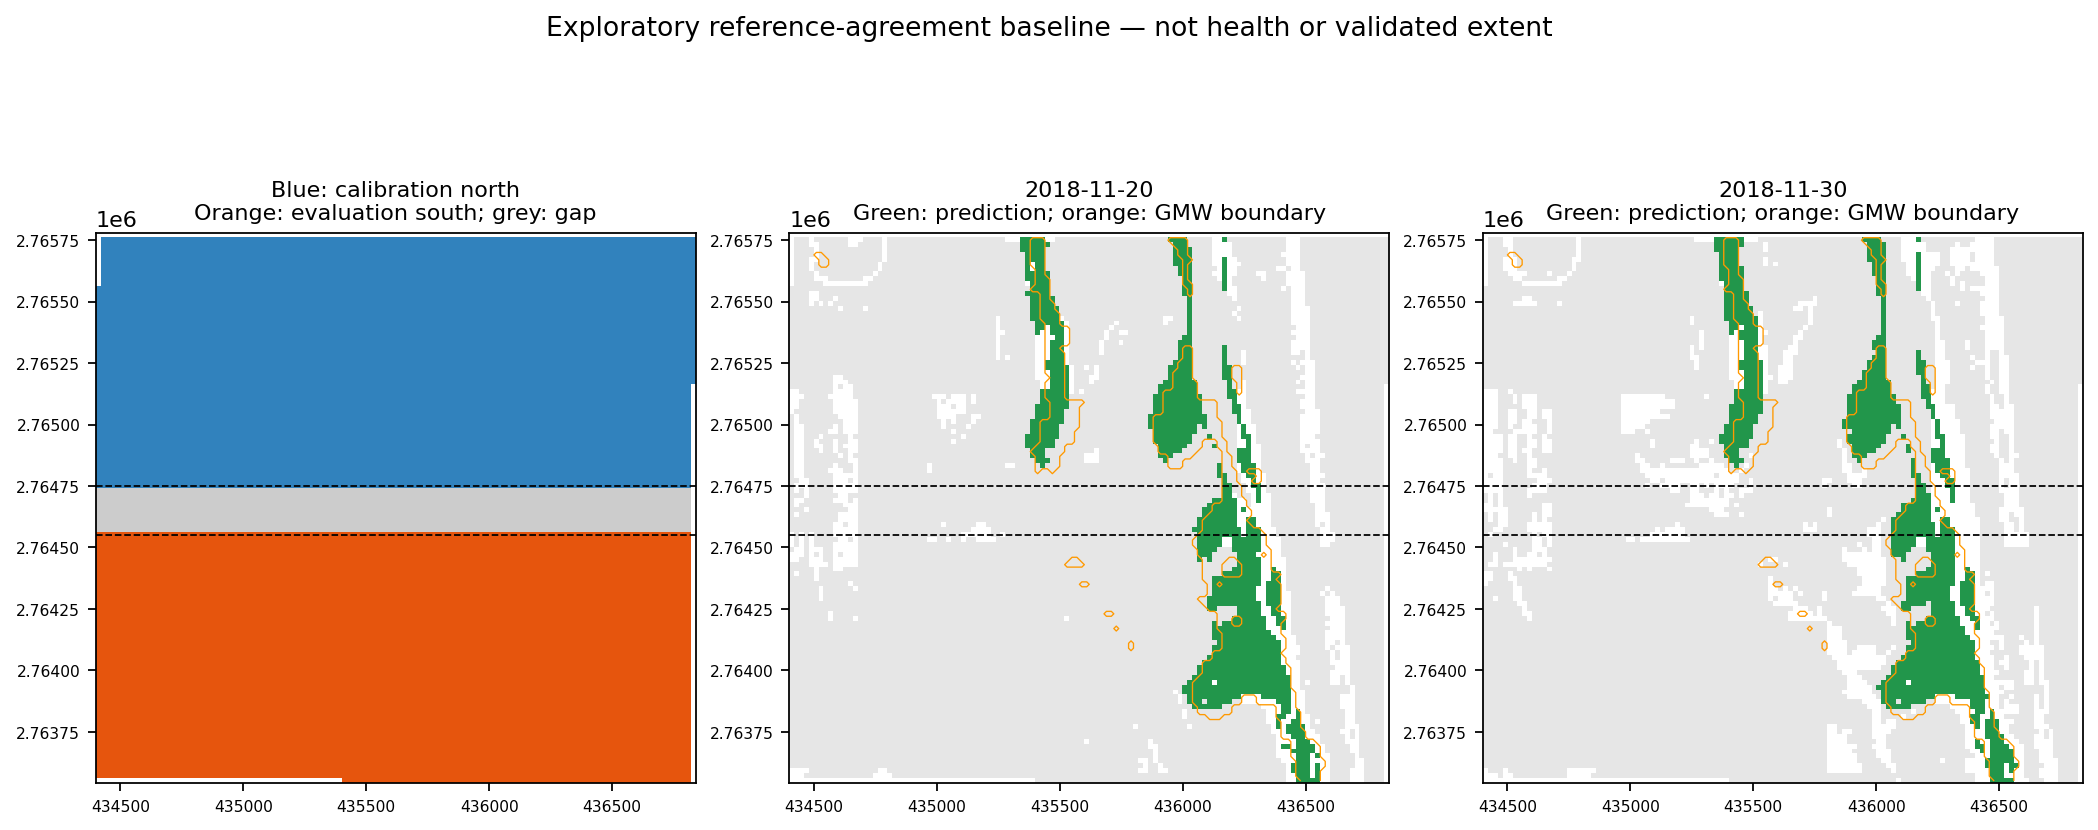

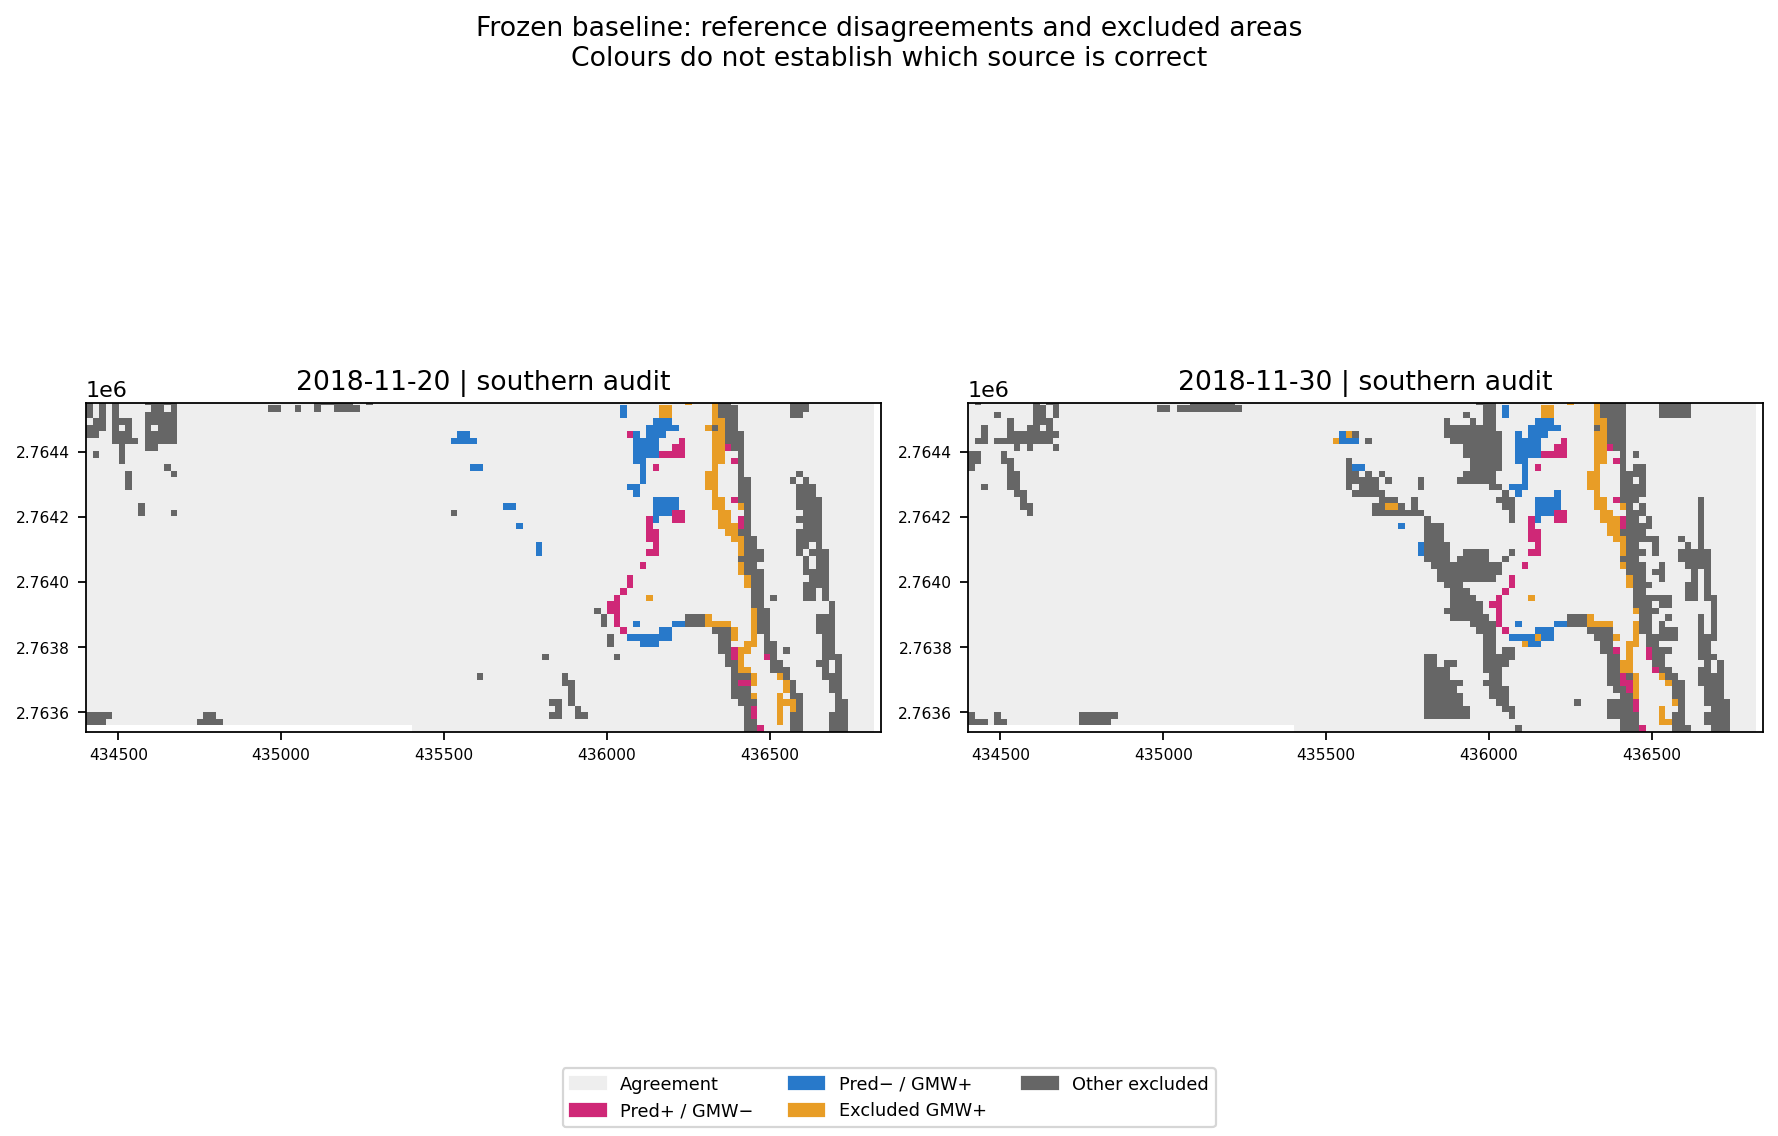

In [8]:
if STATE['status']=='dependencies_ready':
    try:
        REPRO=RUN/'reproduction'
        command([str(PY),str(ROOT/'src/run_submission.py'),'--root',str(ROOT),'--out',str(REPRO)],
                'reproduction_console',750,ENV)
        report=json.loads((REPRO/'run_status.json').read_text())
        if report.get('status')!='succeeded': raise RuntimeError('Runner did not report success')
        STATE.update(status='reproduced',reproduction='succeeded')
        display(Markdown('**RESULT: frozen baseline and audit reproduced and matched.** Not field accuracy.'))
        summary=json.loads((REPRO/'baseline/baseline_summary.json').read_text())
        table=['| Southern reference agreement | Nov 20, 2018 | Nov 30, 2018 |',
               '|---|---:|---:|']
        for label,key in [('Precision','precision'),('Recall','recall'),('F1','f1'),('IoU','iou')]:
            values=[summary['held_out'][d]['all_eligible_southern_cells'][key] for d in ['2018-11-20','2018-11-30']]
            table.append(f'| {label} | {values[0]:.4f} | {values[1]:.4f} |')
        display(Markdown('\n'.join(table)))
        print('Northern calibration F1:',round(summary['calibration']['f1'],4),'— not regional generalization')
        display(Image(filename=str(REPRO/'baseline/baseline_inspection.png'),width=1100))
        display(Image(filename=str(REPRO/'audit/audit_overview.png'),width=1100))
    except Exception as exc:
        STATE.update(status='failed_reproduction_or_display',error=str(exc))
        (RUN/'reproduction_failure.log').write_text(traceback.format_exc())
        print('Reproduction/display failed. Do not use partial files as success:',exc)
else: print('Reproduction skipped: inputs/dependencies failed.')
record()


## 3. Saved reference context

The team-run reference experiment (1 October 2026) compares GMW v3 and v4.1.12 2018 at all 13,401 AOI centres, a different population from the baseline's eligible southern-only denominator. WorldCover 2020 is later-date context and uses GMW as an auxiliary input. Shared lineage and different sampling/representation prevent interpreting these maps as independent ground truth or ecological change.

The following figures and counts come from the saved records; this cell does not compute new reference maps. The earlier GE01 review used imagery dated 5 October 2018, before the Sentinel dates, with alignment uncertainty. This notebook records the review context without loading that imagery.


SAVED PRIOR RESULT: {
  "both_not_mapped": 11806,
  "v3_only_mapped": 177,
  "v4_only_mapped": 437,
  "both_mapped": 981,
  "centres": 13401,
  "differently_mapped_centres": 614,
  "differently_mapped_fraction": 0.04581747630773823,
  "mapped_jaccard": 0.6150470219435736,
  "interpretation": "Reference-map agreement, not field accuracy or ecological change"
}
Among mapped union: 614 / 1595 differ


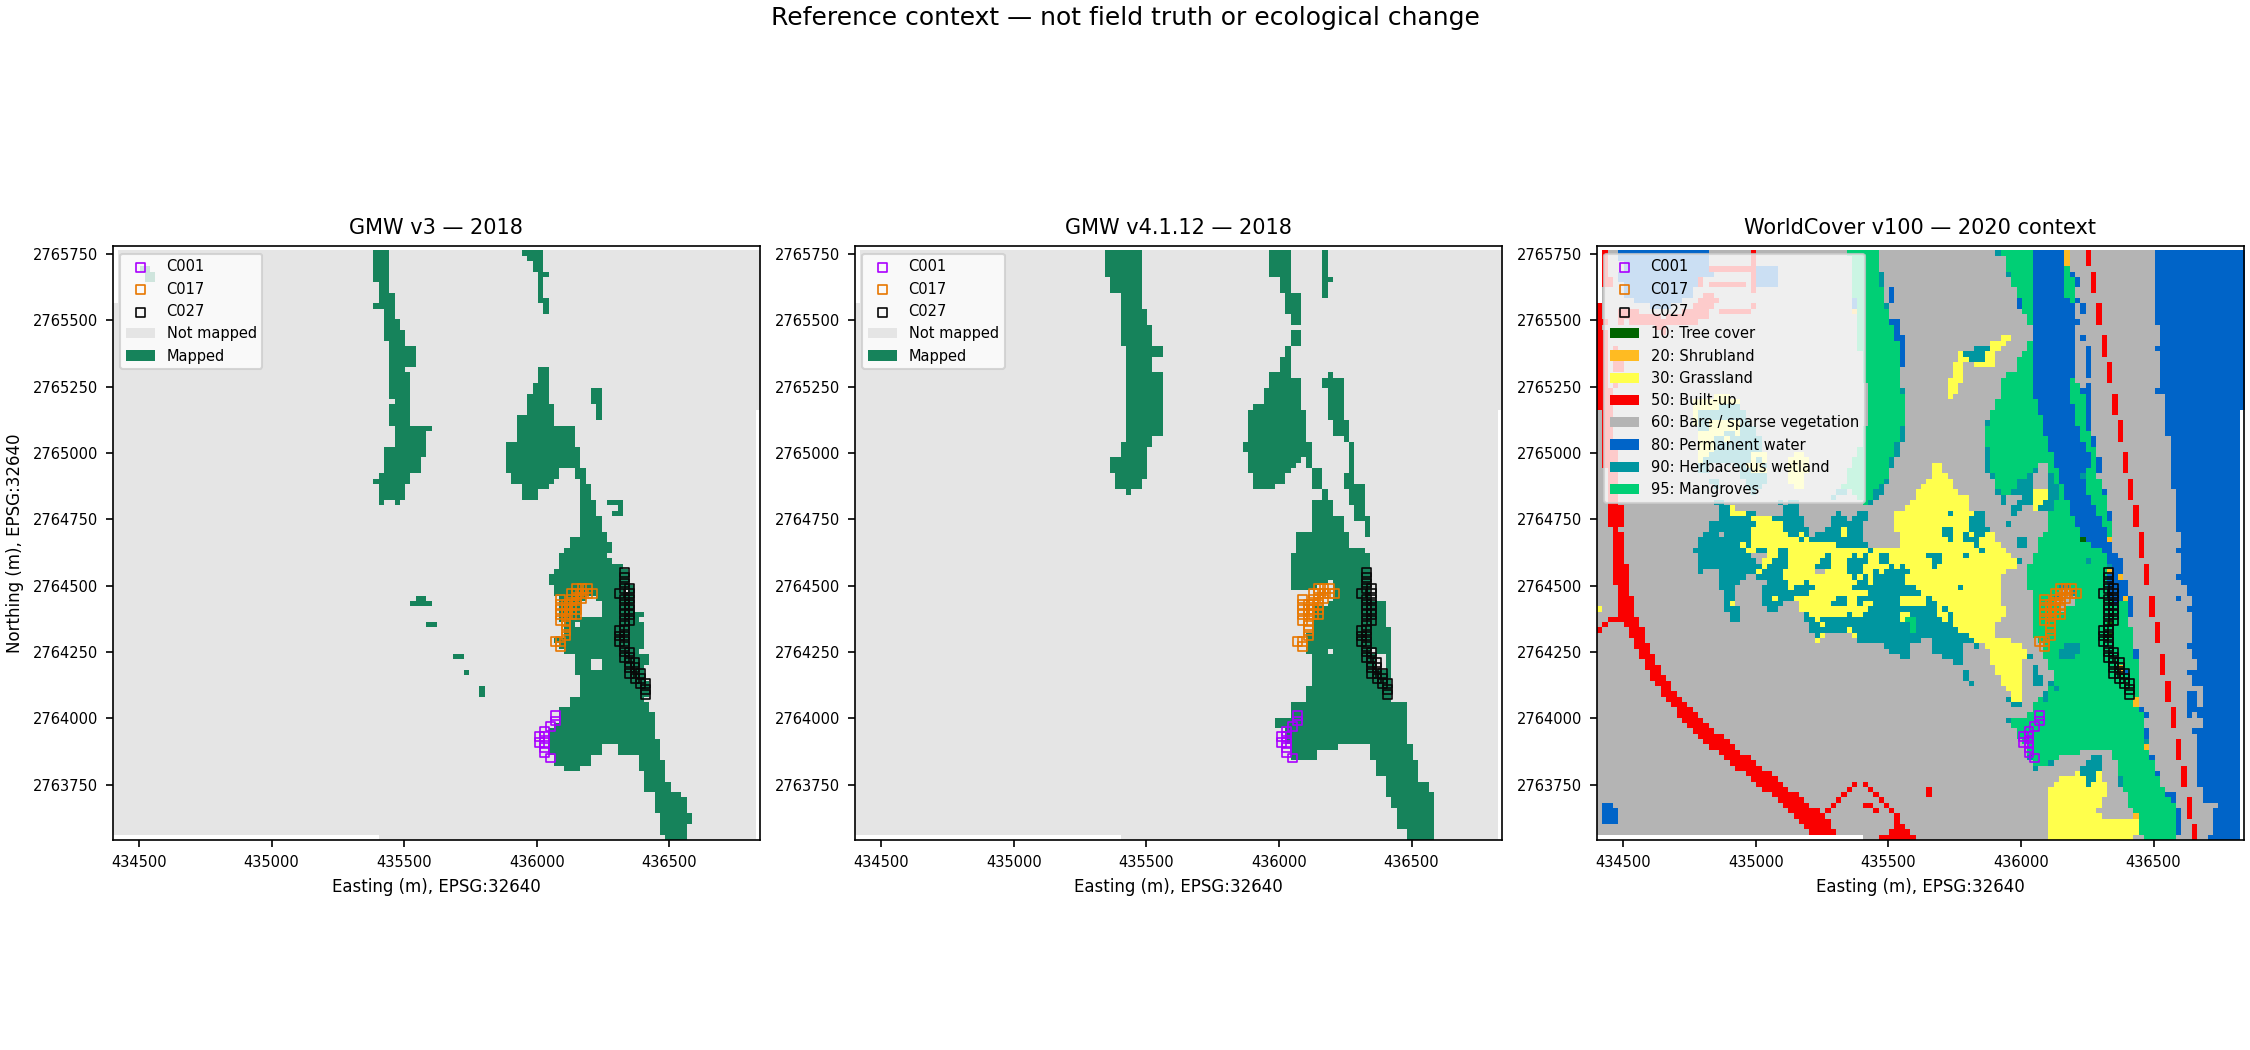

### C001 — Prediction positive / GMW not mapped

**Observation question:** Which target cells and surroundings contain identifiable canopy at the observation date, and how certain is the edge alignment?

**Candidate method:** Existing licensed imagery or safe shore/boat photography; ordinary RGB drone only if access and observation quality justify it

**Amphibious need:** Not established for photographic canopy-edge review

Historical targets: 11; field observations: **0**.

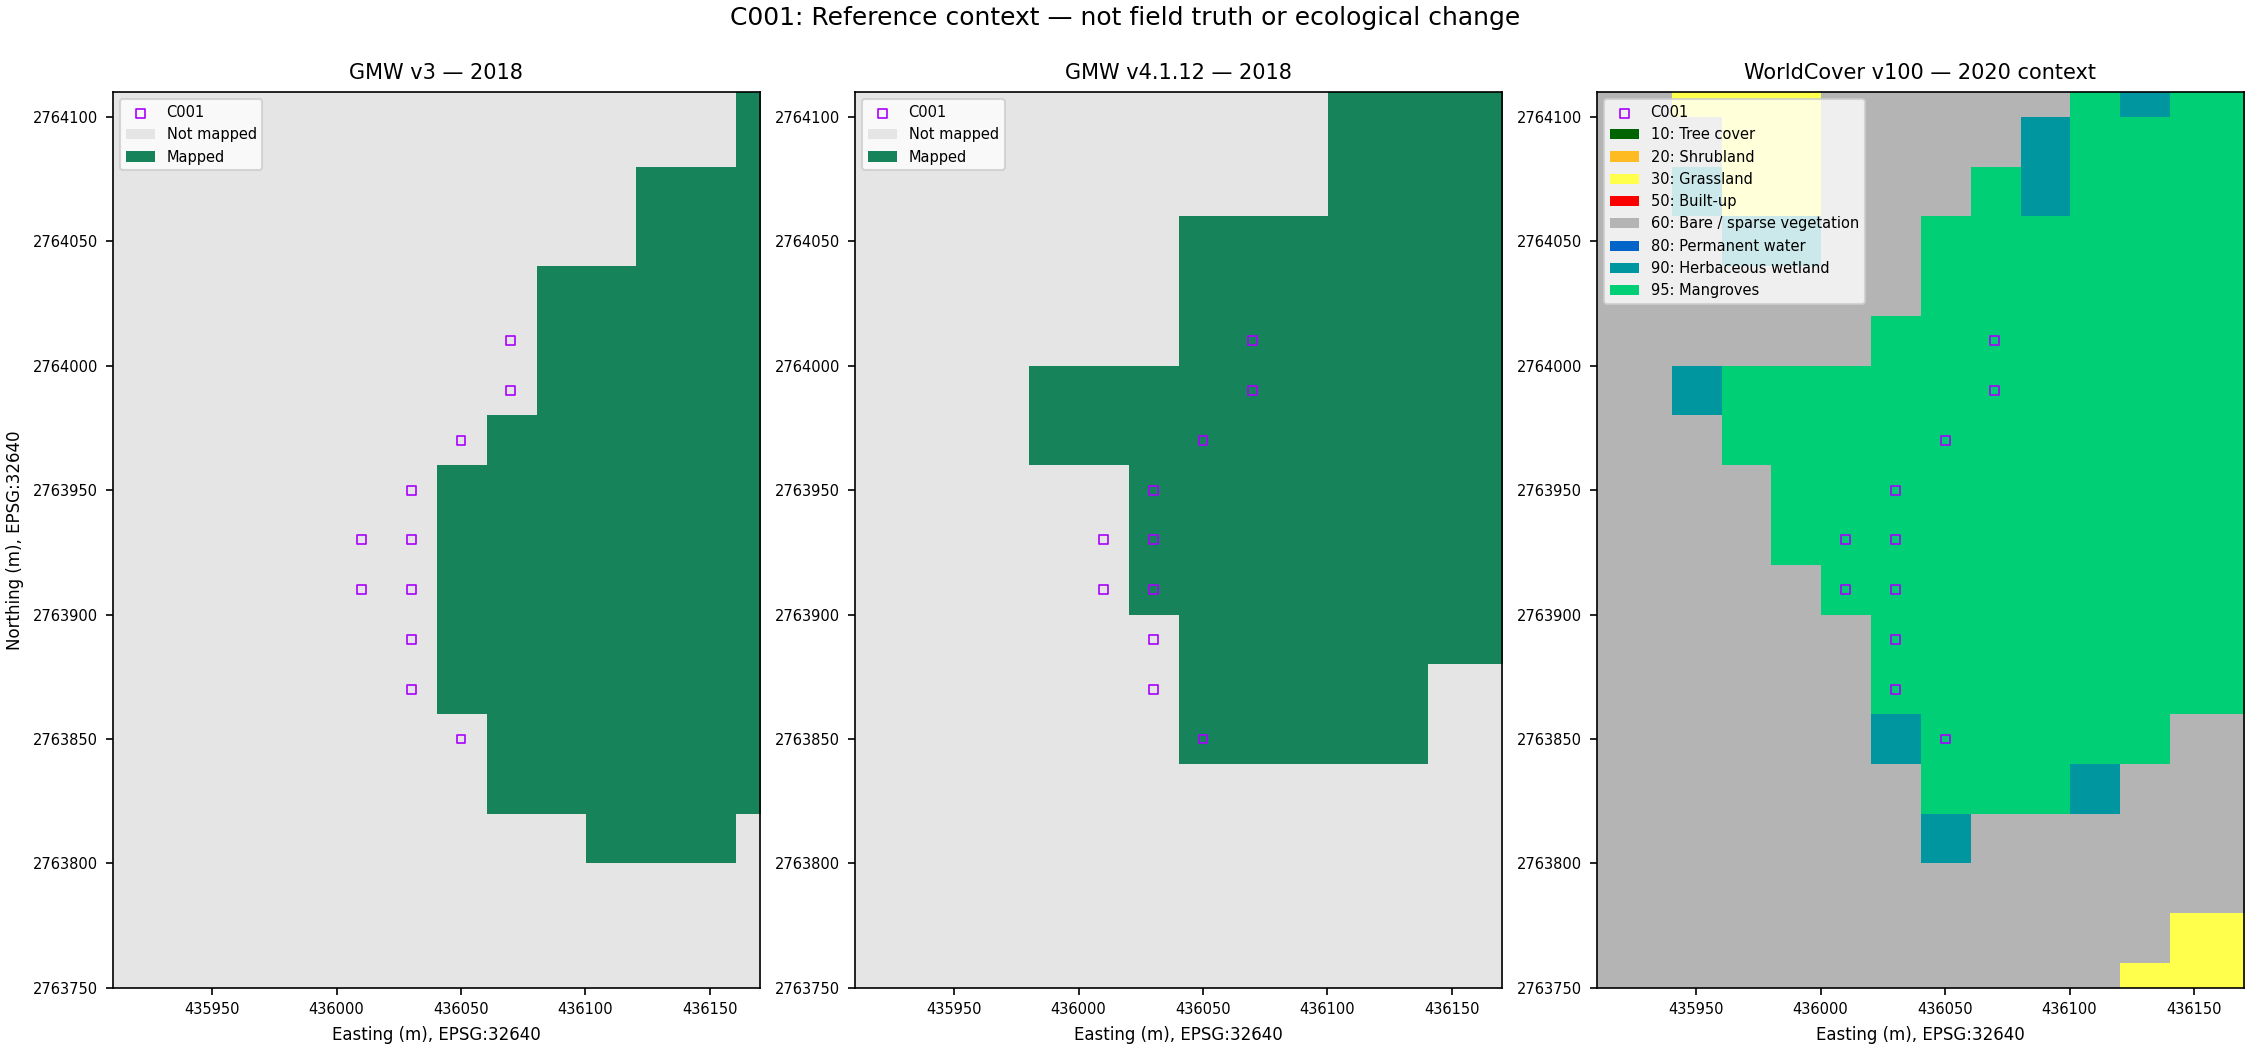

### C017 — Prediction negative / GMW mapped

**Observation question:** What cover composition can be supported for each cell, including mixed vegetation, water and open ground?

**Candidate method:** Detailed licensed imagery, shore/boat photography or ordinary RGB drone where justified

**Amphibious need:** Not established for photographic mixed-cover review

Historical targets: 32; field observations: **0**.

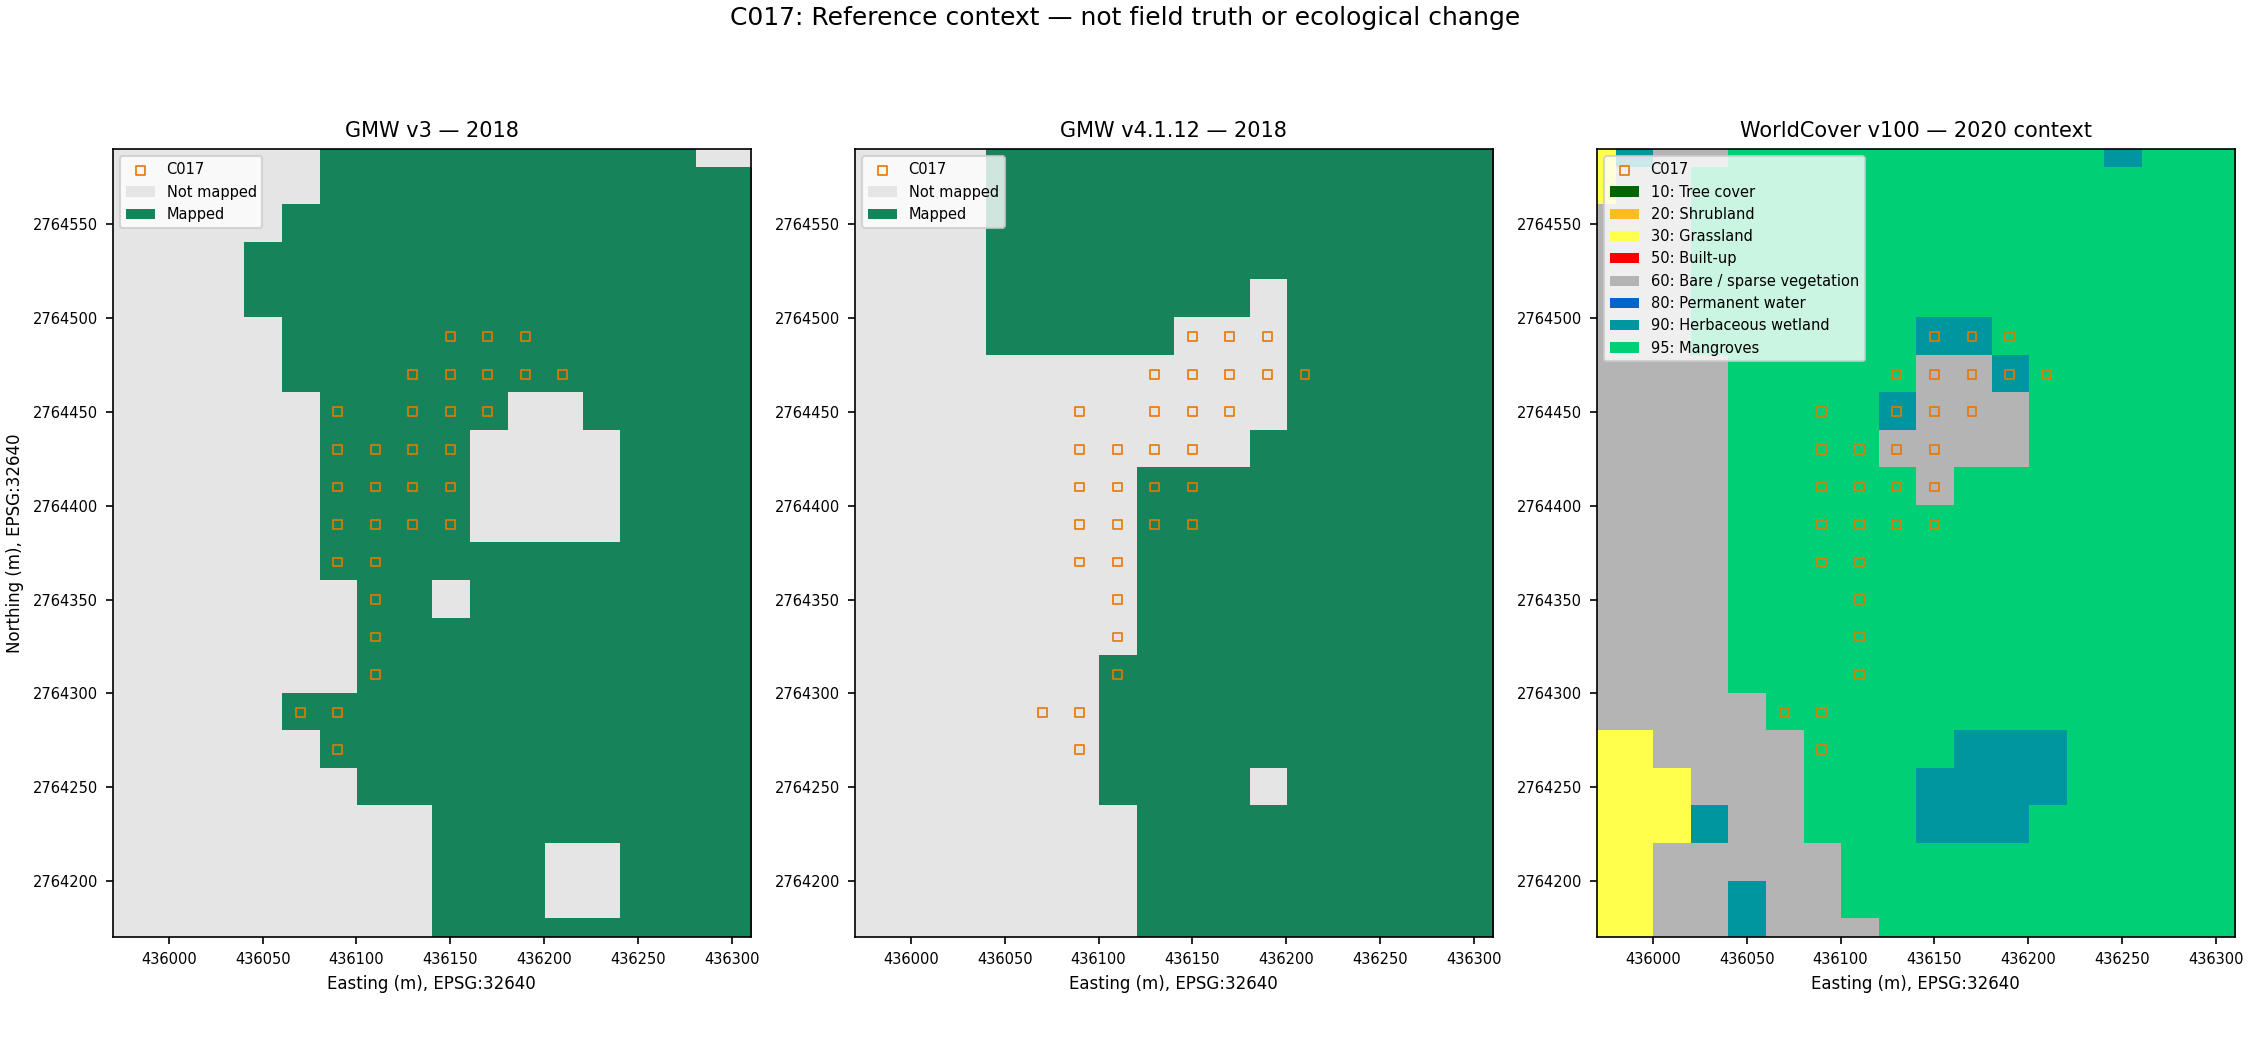

### C027 — Quality-excluded / GMW mapped

**Observation question:** What dated cover evidence is available at the channel margin, and what limits the original usable satellite coverage?

**Candidate method:** Historical source review first; current channel-edge photography only as a separate workflow trial

**Amphibious need:** Conditional separate current contact-sensing hypothesis, not inferred from exclusions

Historical targets: 42; field observations: **0**.

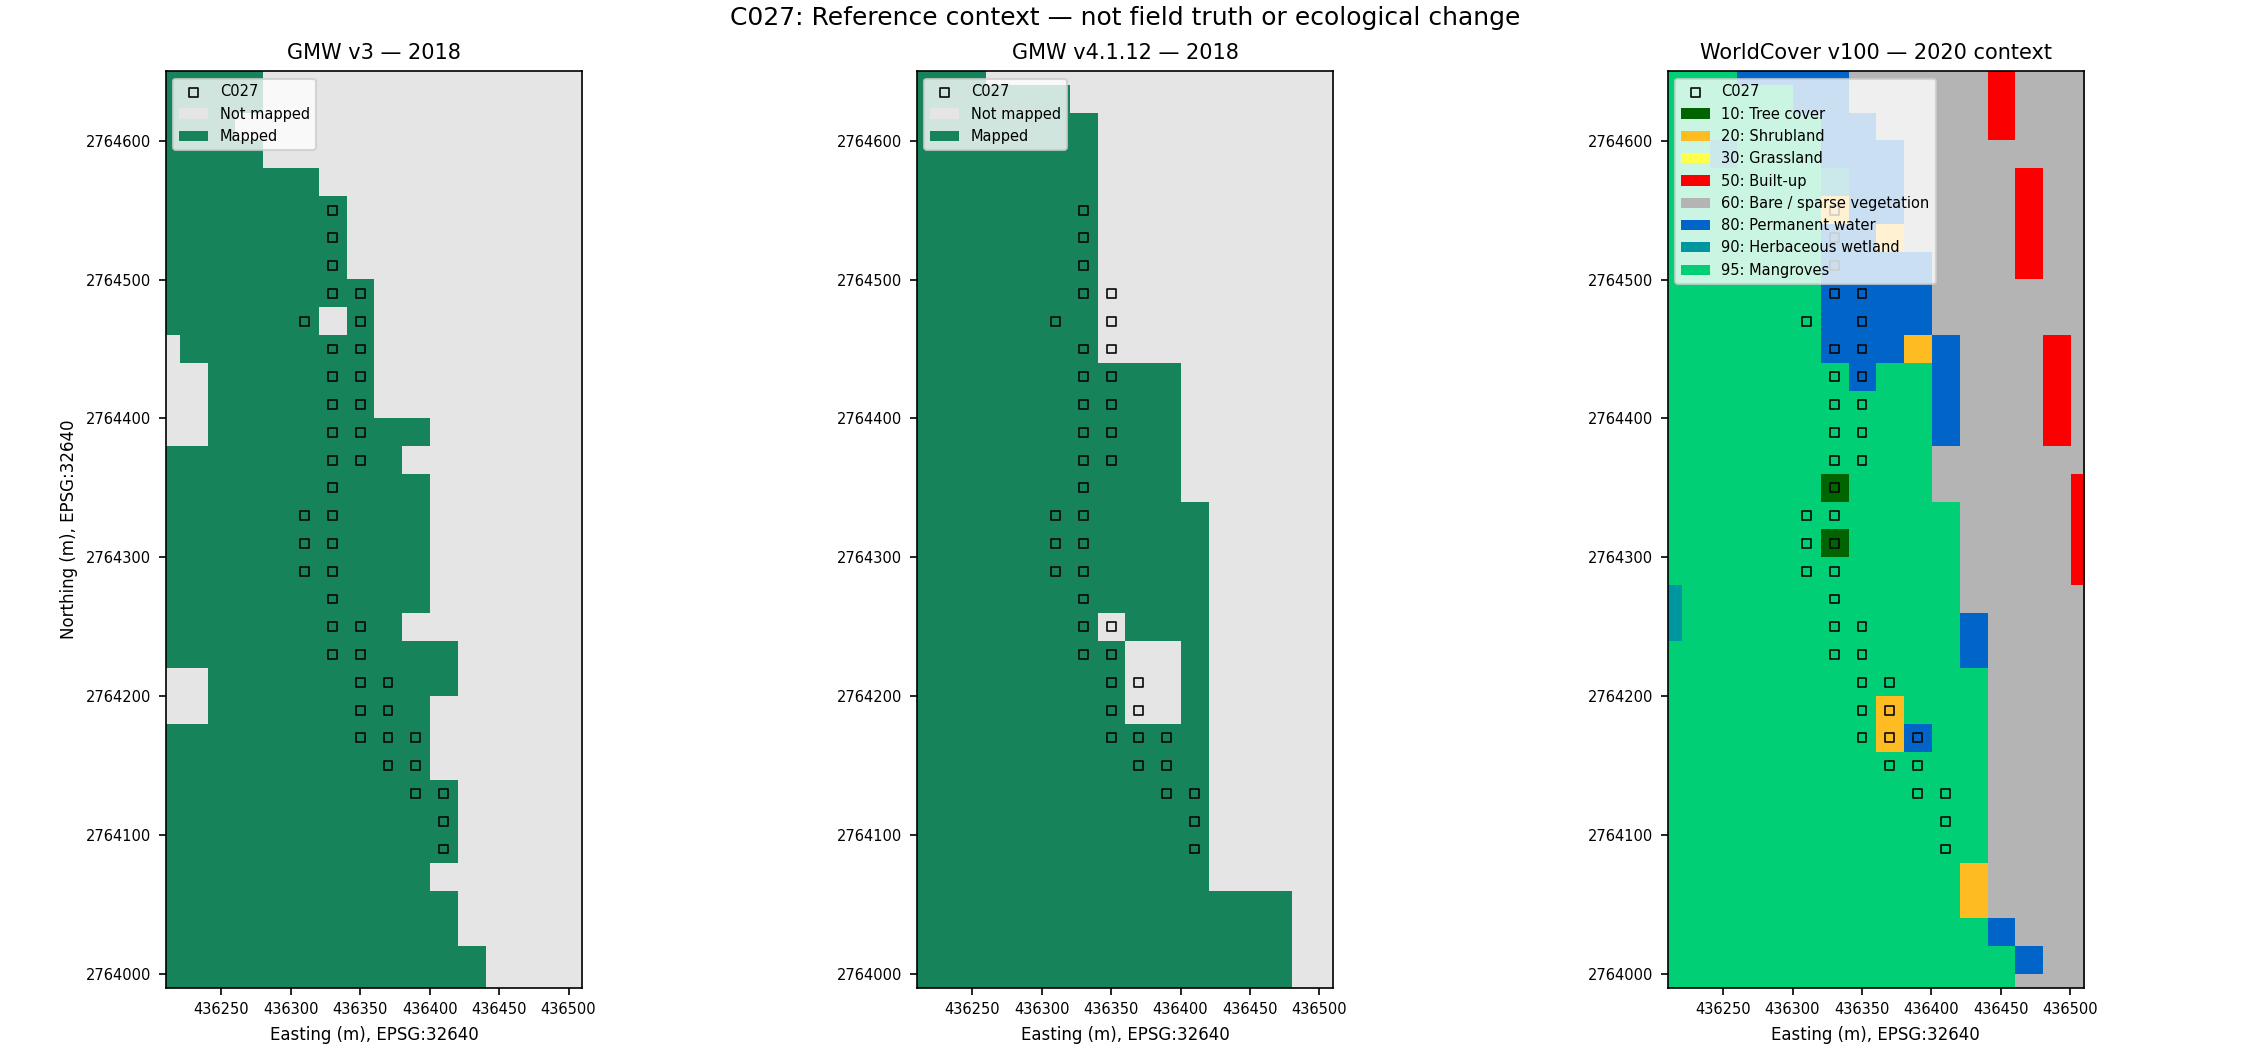

In [9]:
if STATE['reproduction']=='succeeded' and STATE['status']=='reproduced':
    try:
        saved=json.loads((ROOT/'examples/reference_context/comparison_summary.json').read_text())
        context=saved['full_aoi_gmw2018']
        print('SAVED PRIOR RESULT:',json.dumps(context,indent=2))
        union=context['v3_only_mapped']+context['v4_only_mapped']+context['both_mapped']
        print('Among mapped union:',context['differently_mapped_centres'],'/',union,'differ')
        display(Image(filename=str(ROOT/'examples/reference_context/reference_context_overview.png'),width=1100))
        requests=json.loads((ROOT/'examples/inspection/inspection_requests.json').read_text())
        for case in requests['cases']:
            cid=case['case_id']
            display(Markdown('### '+cid+' — '+case['original_category']+'\n\n'+
                '**Observation question:** '+case['question']+'\n\n'+
                '**Candidate method:** '+case['candidate_method']+'\n\n'+
                '**Amphibious need:** '+case['amphibious_need']+'\n\n'+
                'Historical targets: '+str(case['target_count'])+'; field observations: **0**.'))
            display(Image(filename=str(ROOT/f'examples/reference_context/{cid}_reference_context.png'),width=1000))
        STATE['status']='context_displayed'
    except Exception as exc:
        STATE.update(status='failed_context_display',error=str(exc))
        (RUN/'context_failure.log').write_text(traceback.format_exc())
        print('Saved context display failed:',exc)
else: print('Review display skipped: clean reproduction required.')
record()


## 4. Validate and export inspection requests

The implemented handoff packages traceable requests rather than operating a drone. Standard-library tests detect tampered coordinates, source labels, dates, memberships, invented measurements/conclusions and unsafe export paths. Targets are original historical cell centres, not flight waypoints, access routes, landing positions or approved water-contact sites.

The exported CSV keeps target coordinates distinct from actual observation coordinates. Measurement fields remain empty. No planting recommendation is made; field access and habitat-disturbance permissions are unconfirmed.


In [10]:
if STATE['status']=='context_displayed':
    try:
        TEST_TMP=RUN/'format_test_tmp'; TEST_TMP.mkdir()
        test_env=ENV.copy(); test_env['MP_FORMAT_TEST_TMP']=str(TEST_TMP)
        command([str(PY),'-B','-m','unittest','discover','-s',str(ROOT/'tests'),'-p',
                 'test_inspection_handoff.py','-v'],'handoff_format_tests',120,test_env)
        command([str(PY),str(ROOT/'src/inspection_handoff.py'),'--root',str(ROOT),
                 '--out',str(RUN/'inspection_export')],'inspection_export',120,ENV)
        validation=json.loads((RUN/'inspection_export/validation.json').read_text())
        if validation.get('status')!='format_and_traceability_passed': raise RuntimeError('Handoff did not pass')
        STATE.update(status='handoff_verified',handoff='format_and_traceability_passed')
        print(json.dumps(validation,indent=2))
        display(Markdown('**85 historical centres exported; zero collected observations.**\n\n'+
            'Files: inspection requests, GeoJSON, blank JSON return template, '+
            '85-row observations_UNFILLED.csv, attribution and validation record.'))
    except Exception as exc:
        STATE.update(status='failed_handoff',error=str(exc))
        (RUN/'handoff_failure.log').write_text(traceback.format_exc())
        print('Handoff failed:',exc)
else: print('Export skipped: clean reproduction and context display required.')
record()


test_context_change_rejected (test_inspection_handoff.HandoffTests.test_context_change_rejected) ... ok
test_coordinate_change_rejected (test_inspection_handoff.HandoffTests.test_coordinate_change_rejected) ... ok
test_date_change_rejected (test_inspection_handoff.HandoffTests.test_date_change_rejected) ... ok
test_duplicate_target_rejected (test_inspection_handoff.HandoffTests.test_duplicate_target_rejected) ... ok
test_each_missing_observation_field_rejected (test_inspection_handoff.HandoffTests.test_each_missing_observation_field_rejected) ... ok
test_export_empty_csv_and_source_identity (test_inspection_handoff.HandoffTests.test_export_empty_csv_and_source_identity) ... ok
test_fabricated_conclusion_rejected (test_inspection_handoff.HandoffTests.test_fabricated_conclusion_rejected) ... ok
test_flight_waypoint_claim_rejected (test_inspection_handoff.HandoffTests.test_flight_waypoint_claim_rejected) ... ok
test_missing_case_membership_rejected (test_inspection_handoff.HandoffTests.te

**85 historical centres exported; zero collected observations.**

Files: inspection requests, GeoJSON, blank JSON return template, 85-row observations_UNFILLED.csv, attribution and validation record.

## 5. Conditional drone hypothesis, with an explicit rejection case

The prior theoretical energy experiment assumes three hypothetical sites, not the three Khor Kalba clusters or a derived route. At 150 s dwell/site, the selected calculation was approximately 170.7 Wh hovering versus 128.0 Wh supported (~25% lower); break-even was about 84.2 s under those assumptions. Short dwell or support overhead reverses the advantage. Equal accepted observation quality, safe transitions, environmental acceptability and actual energy consumption remain unmeasured. Supported operation is slower in the selected scenario; energy savings alone do not establish mission feasibility.

An amphibious platform merits a later trial only if a defined contact-observation task cannot be served adequately by licensed imagery, shore/boat methods or an ordinary drone. Compare energy/time per accepted observation, safety, habitat disturbance, data quality and payload mass against those alternatives using a predeclared protocol. Reject the concept if it fails safety/permission/quality gates or adds no benefit. This research hypothesis does not establish superiority over an existing UAE product.


In [11]:
if STATE['status']=='handoff_verified':
    try:
        energy=json.loads((ROOT/'examples/inspection/energy_scenario_excerpt.json').read_text())
        rows=['| Saved hypothetical case | Hover Wh | Supported Wh | Supported lower? |',
              '|---|---:|---:|---|']
        for name,case in energy['illustrative_cases'].items():
            r=case['result']
            rows.append(f"| {name} | {r['hover_energy_wh']:.1f} | {r['supported_energy_wh']:.1f} | {r['supported_energy_lower']} |")
        display(Markdown('\n'.join(rows)))
        print('SAVED RESULT ONLY — no aircraft/model execution in this notebook.')
        print('Observation equivalence and operational feasibility: NOT ESTABLISHED.')
        STATE['status']='succeeded'
    except Exception as exc:
        STATE.update(status='failed_energy_display',error=str(exc))
        (RUN/'energy_display_failure.log').write_text(traceback.format_exc())
        print('Saved energy display failed:',exc)
else: print('Conditional-energy display skipped: handoff did not pass.')
record()


| Saved hypothetical case | Hover Wh | Supported Wh | Supported lower? |
|---|---:|---:|---|
| short_dwell | 88.8 | 124.0 | False |
| illustrative_main | 170.7 | 128.0 | True |
| long_dwell | 273.2 | 133.0 | True |
| long_route_energy_only_win | 478.1 | 416.9 | True |
| extra_80_wh_overhead | 170.7 | 208.0 | False |

SAVED RESULT ONLY — no aircraft/model execution in this notebook.
Observation equivalence and operational feasibility: NOT ESTABLISHED.


## 6. Download results or diagnostics

The final cell packages logs and explicit status. Only status: succeeded identifies a successful integrated demonstration of reproducibility and traceable packaging, not field accuracy, ecological need or drone superiority. Saved-context files and hypothetical-energy records are labelled separately from new reproduction outputs. The package excludes the virtual environment and private account data.

Save the notebook with visible outputs after running; the results ZIP alone does not replace the executed-notebook deliverable. The required pitch PDF and authorized repository publication/access remain separate delivery steps. Review distribution rights and source notices before delivery; choosing an original-code licence is recommended, not an established mandatory requirement.


In [12]:
STATE['finished_utc']=datetime.now(timezone.utc).isoformat()
record()
review=RUN/'review_docs'; review.mkdir(exist_ok=True)
if 'ROOT' in globals() and ROOT is not None and ROOT.is_dir():
    for name in ['DRONE_KHOR_KALBA_HANDOFF.md','POC_LOGIC_AND_NEXT_STEP.md',
                 'C001_INSPECTION_BRIEF.md','C017_INSPECTION_BRIEF.md','C027_INSPECTION_BRIEF.md']:
        p=ROOT/'docs'/name
        if p.is_file(): (review/name).write_bytes(p.read_bytes())
    attribution=ROOT/'ATTRIBUTION.md'
    if attribution.is_file(): (review/'ATTRIBUTION.md').write_bytes(attribution.read_bytes())
    if STATE['status']=='succeeded':
        context_out=RUN/'saved_prior_reference_context'; context_out.mkdir(exist_ok=True)
        for p in (ROOT/'examples/reference_context').iterdir():
            if p.suffix=='.png' or p.name in ['comparison_summary.json','case_comparison.json','run_status.json','METHOD.md','ATTRIBUTION.md']:
                (context_out/p.name).write_bytes(p.read_bytes())
        (RUN/'saved_hypothetical_energy.json').write_bytes((ROOT/'examples/inspection/energy_scenario_excerpt.json').read_bytes())
    pins=ROOT/'requirements.txt'
    if pins.is_file(): (RUN/'dependency_pins.txt').write_bytes(pins.read_bytes())
payload=[]
for p in RUN.rglob('*'):
    if not p.is_file(): continue
    relative=p.relative_to(RUN)
    if relative.parts[0] in ['venv','repository','mplconfig','format_test_tmp'] or p.name in ['repository.zip','output_manifest.json']: continue
    payload.append(p)
manifest={p.relative_to(RUN).as_posix():hashlib.sha256(p.read_bytes()).hexdigest() for p in sorted(payload)}
(RUN/'output_manifest.json').write_text(json.dumps(manifest,indent=2)+'\n')
archive=RUN.parent/(RUN.name+'_results.zip')
with zipfile.ZipFile(archive,'w',zipfile.ZIP_DEFLATED) as z:
    for p in sorted(payload)+[RUN/'output_manifest.json']: z.write(p,p.relative_to(RUN))
print('STATUS:',STATE['status'])
print('ZIP:',archive.name,'bytes:',archive.stat().st_size,'SHA-256:',hashlib.sha256(archive.read_bytes()).hexdigest())
print('Manifest excludes itself. No observation or drone operational validation is claimed.')
if STATE['status']!='succeeded': print('DIAGNOSTICS ONLY. Return ZIP for repair; do not call this completed results.')
try:
    from google.colab import files
    files.download(str(archive))
except ImportError: print('Outside Colab; result ZIP is at:',archive)


STATUS: succeeded
ZIP: mangrove_pulse_end_to_end_sq06rrmp_results.zip bytes: 2103306 SHA-256: ca8c84c157194b948b0600d4438080e2365370add803dcc8b6d5805e2669a398
Manifest excludes itself. No observation or drone operational validation is claimed.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>